In [ ]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from tqdm import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score,cross_val_predict,cross_validate,train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,precision_recall_curve
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay, ConfusionMatrixDisplay
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv('C:\\Users\\HP\\Downloads\\source_amazon\\titanic.csv')

In [6]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
# Check the value counts of the 'Embarked' column
df['Embarked'].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

In [8]:
import seaborn as sns

In [9]:
def countplot(df,x,b,title, xlabel):
    plt.figure(figsize=(8,6))
    sns.countplot(
        data= df,
        x=x,
        hue= b,
        palette=['red', 'green']

    )
    plt.legend(['Not Survived', 'Survived'])
    plt.xlabel(xlabel)
    plt.ylabel('Survival Count')
    plt.title(title)
    plt.show()

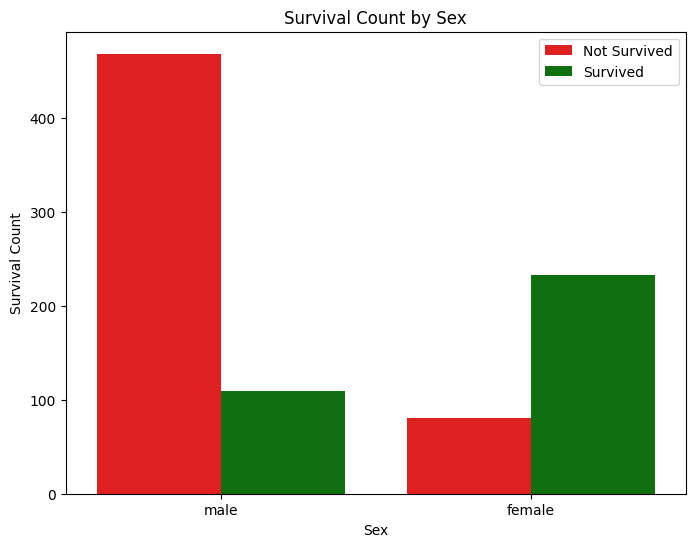

In [10]:
countplot(df,'Sex','Survived','Survival Count by Sex','Sex')

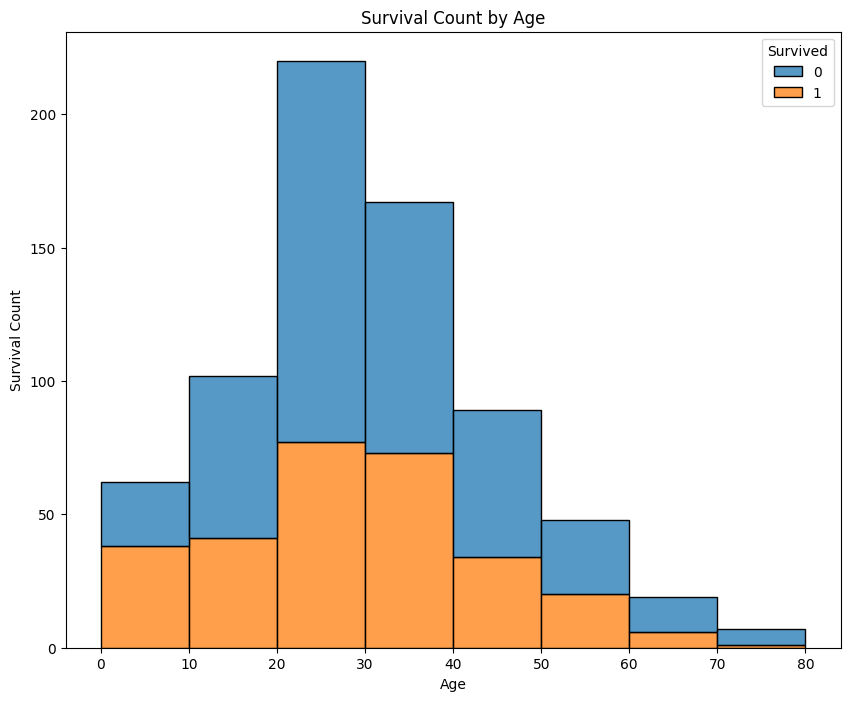

In [11]:
def histogram(df,x,b,title,xlabel):
    plt.figure(figsize=(10,8))
    bin_edges = list(range(0, 81, 10))
    sns.histplot(
        data=df,
        x=x,
        hue=b,
        multiple='stack',
        bins=bin_edges,
        # binwidth=10
        # bins=[]
    )
    plt.xlabel(xlabel)
    plt.ylabel('Survival Count')
    plt.title(title)
    plt.show()
histogram(df,'Age','Survived','Survival Count by Age','Age')

In [12]:
confusion_matrix(df['Survived'], df['Sex'].map({'male': 0, 'female': 1}))

array([[468,  81],
       [109, 233]])

Text(0.5, 1.0, 'Correlation Matrix')

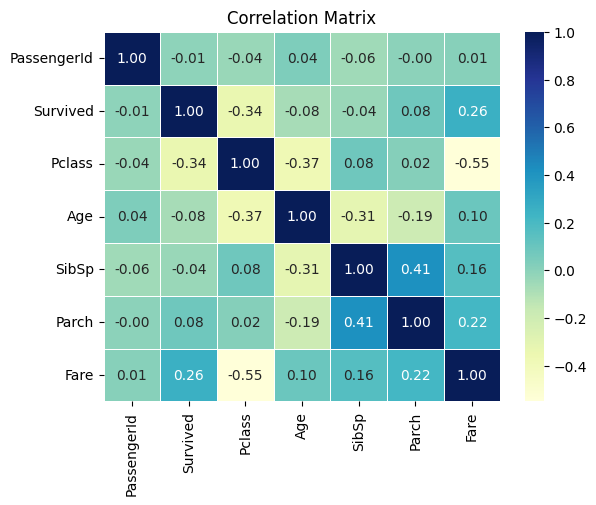

In [13]:

correlation_matrix = df.corr(numeric_only=True, method='pearson', min_periods=1)
# correlation_matrix = df.corr()
# plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')

In [14]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [15]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

# Handling the null values

In [16]:
df['Cabin'].isnull().sum()

np.int64(687)

In [17]:
df_copy = df.copy()

In [26]:
df.drop(columns=['Cabin'])

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,first_name
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5,7.2500,S,Mr.
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC,71.2833,C,Mrs.
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2.,7.9250,S,Miss.
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,X,53.1000,S,Mrs.
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,X,8.0500,S,Mr.
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",0,27.0,0,0,X,13.0000,S,Rev.
887,888,1,1,"Graham, Miss. Margaret Edith",1,19.0,0,0,X,30.0000,S,Miss.
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",1,NaN,1,2,W./C.,23.4500,S,Miss.
889,890,1,1,"Behr, Mr. Karl Howell",0,26.0,0,0,X,30.0000,C,Mr.


In [97]:
df['Ticket']= df_copy['Ticket']
# Count how many times each ticket appears
ticket_counts = df['Ticket'].value_counts()

# Create a new feature for Ticket Group Size
df['Ticket_Group_Size'] = df['Ticket'].map(ticket_counts)

# Now drop the original messy text column
df = df.drop(columns=['Ticket'])

In [ ]:
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

In [55]:
df['Sex']=df_copy['Sex'].map({'male':0, 'female':1 })

In [ ]:
df['Sex'] = df['Sex'].map({'male':0, 'female':1})

In [33]:
df['Name'].value_counts()

Name
Dooley, Mr. Patrick                                    1
Braund, Mr. Owen Harris                                1
Cumings, Mrs. John Bradley (Florence Briggs Thayer)    1
Heikkinen, Miss. Laina                                 1
Futrelle, Mrs. Jacques Heath (Lily May Peel)           1
                                                      ..
Hewlett, Mrs. (Mary D Kingcome)                        1
Vestrom, Miss. Hulda Amanda Adolfina                   1
Andersson, Mr. Anders Johan                            1
Saundercock, Mr. William Henry                         1
Bonnell, Miss. Elizabeth                               1
Name: count, Length: 891, dtype: int64

In [34]:
df['first_name'] = df['Name'].apply(lambda x: x.split(',')[1].strip().split()[0] if len(x.split(',')) > 1 else x)

In [35]:
df['first_name'].value_counts()

first_name
Mr.          517
Miss.        182
Mrs.         125
Master.       40
Dr.            7
Rev.           6
Col.           2
Mlle.          2
Major.         2
Ms.            1
Mme.           1
Don.           1
Lady.          1
Sir.           1
Capt.          1
the            1
Jonkheer.      1
Name: count, dtype: int64

In [40]:
def Age_group(age):
    if age < 18:
        return 0
    elif 18 <= age < 40:
        return 1
    else:
        return 2
age_groups = df['Age'].apply(Age_group)

In [41]:
df['Age_group'] = age_groups


In [57]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

In [ ]:
label_encoder.fit(df['Embarked'])
df['Embarked_encoded'] = label_encoder.transform(df['Embarked'])



In [60]:
df['Embarked_encoded'].value_counts()

Embarked_encoded
2    646
0    168
1     77
Name: count, dtype: int64

In [90]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,first_name,Age_group,Embarked_encoded,Ticket_encoded
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,7.2500,Mr.,1,2,7
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,71.2833,Mrs.,1,0,4
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,7.9250,Miss.,1,2,7
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,53.1000,Mrs.,1,2,7
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,8.0500,Mr.,1,2,7


In [86]:
df['Ticket'].value_counts()

Ticket
X    891
Name: count, dtype: int64

In [ ]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# Optional: Create an 'IsAlone' flag since solo travelers had different survival odds
df['IsAlone'] = 0
df.loc[df['FamilySize'] == 1, 'IsAlone'] = 1

# You can optionally drop the old columns if you no longer need them separately
df = df.drop(columns=['SibSp', 'Parch'])

In [ ]:
# # Drop PassengerId from your features
# X = df.drop(columns=['PassengerId', 'Survived']) # Ensure 'Survived' is also dropped if it's your target
# y = df['Survived']

# # Re-run your train_test_split, cross-validation, and feature importances
# df

,PassengerId,Survived,Pclass,Name,Sex,Age,Fare,first_name,Age_group,Embarked_encoded,Ticket_encoded,Ticket_Group_Size,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,7.2500,Mr.,1,2,7,1,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,71.2833,Mrs.,1,0,4,1,2,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,7.9250,Miss.,1,2,7,1,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,53.1000,Mrs.,1,2,7,2,2,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,8.0500,Mr.,1,2,7,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",0,27.0,13.0000,Rev.,1,2,7,1,1,1
887,888,1,1,"Graham, Miss. Margaret Edith",1,19.0,30.0000,Miss.,1,2,7,1,1,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",1,NaN,23.4500,Miss.,2,2,7,2,4,0
889,890,1,1,"Behr, Mr. Karl Howell",0,26.0,30.0000,Mr.,1,0,7,1,1,1


In [152]:

X_train, X_test, y_train, y_test = train_test_split(df.drop(['Survived', 'Name', 'first_name','PassengerId','Ticket_encoded'], axis=1), df['Survived'], stratify=df['Survived'], test_size=0.2, random_state=42)

In [153]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model

RandomForestClassifier(random_state=42)

In [154]:
model_acc = cross_val_score(model, X_train, y_train, cv=7, scoring='accuracy')

In [155]:
model_acc

array([0.79411765, 0.79411765, 0.74509804, 0.82352941, 0.8627451 ,
       0.8019802 , 0.78217822])

In [156]:
print("Average Accuracy:", model_acc.mean())

Average Accuracy: 0.8005380369969769


In [157]:
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [158]:
# 1. Extract importances and map them to column names
importances = model.feature_importances_
feature_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 2. Display the sorted features
print(feature_df)


             Feature  Importance
1                Sex    0.270171
3               Fare    0.237971
2                Age    0.218340
0             Pclass    0.083500
6  Ticket_Group_Size    0.057560
7         FamilySize    0.056004
5   Embarked_encoded    0.032753
4          Age_group    0.029186
8            IsAlone    0.014514


In [159]:
y_pred = model.predict(X_test)

In [160]:
confusion_matrix(y_test, y_pred)

array([[94, 16],
       [22, 47]])

In [161]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, precision_recall_curve
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

precision, recall, thresholds = precision_recall_curve(y_test, y_pred)

Accuracy: 0.7877094972067039
Precision: 0.746031746031746
Recall: 0.6811594202898551
F1 Score: 0.7121212121212122


Text(0.5, 1.0, 'Precision-Recall Curve')

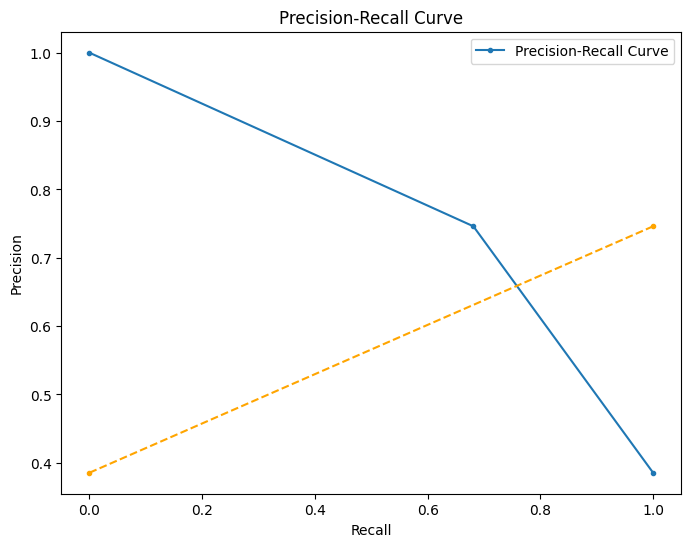

In [162]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.')
plt.plot(thresholds, precision[:-1], marker='.', linestyle='--', color='orange', label='Thresholds')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(['Precision-Recall Curve'])
plt.title('Precision-Recall Curve')

# Using thr GridSearchCV

In [167]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Define the parameters we want to test
param_grid = {
    'n_estimators':[10],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}
# 2. Set up the Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

# 3. Fit it to your training data
grid_search.fit(X_train, y_train)

# 4. Print the best results
print("Best Parameters Found:", grid_search.best_params_)
print(f"Best Tuned Accuracy: {grid_search.best_score_:.4f}")


Best Parameters Found: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 10}
Best Tuned Accuracy: 0.8245


In [170]:
y_pred_grid =grid_search.predict(X_test)

In [172]:
print("Accuracy:", accuracy_score(y_test, y_pred_grid))
print("Precision:", precision_score(y_test, y_pred_grid))
print("Recall:", recall_score(y_test, y_pred_grid))
print("F1 Score:", f1_score(y_test, y_pred_grid))

precision, recall, thresholds = precision_recall_curve(y_test, y_pred_grid)

Accuracy: 0.7877094972067039
Precision: 0.746031746031746
Recall: 0.6811594202898551
F1 Score: 0.7121212121212122


In [174]:
# 1. Initialize a more robust, smoother Random Forest
optimized_model = RandomForestClassifier(
    n_estimators=150,      # Smooths out predictions using a larger pool of trees
    max_depth=6,           # Prevents individual trees from memorizing unique rows
    min_samples_split=5, 
    random_state=42
)

# 2. Fit to training data
optimized_model.fit(X_train, y_train)

# 3. Predict on your test set
y_pred_opt = optimized_model.predict(X_test)

# 4. Check the new scores
print("New Test Accuracy:", accuracy_score(y_test, y_pred_opt))
print("New F1 Score:", f1_score(y_test, y_pred_opt))


New Test Accuracy: 0.7988826815642458
New F1 Score: 0.7


<Figure size 700x500 with 0 Axes>

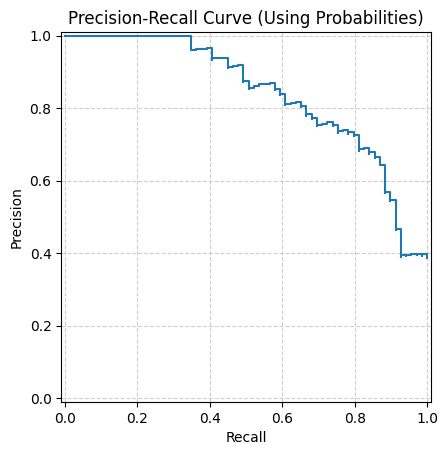

In [ ]:
# 1. Get predicted probabilities for the positive class (Survived = 1)
y_scores = optimized_model.predict_proba(X_test)[:, 1]

# 2. Compute precision and recall values across thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

# 3. Generate a clean visual plot
plt.figure(figsize=(7, 5))
display = PrecisionRecallDisplay(precision=precision, recall=recall)
display.plot()
plt.title("Precision-Recall Curve (Using Probabilities)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


- Top-Left Box (True Negatives): Passengers who actually perished that your model correctly predicted would perish.
- Bottom-Right Box (True Positives): Passengers who actually survived that your model correctly predicted would survive.
- Top-Right Box (False Positives): Passengers who perished, but your model incorrectly guessed would survive (Type I error).
- Bottom-Left Box (False Negatives): Passengers who survived, but your model incorrectly guessed would perish (Type II error).

In [179]:
confusion_matrix(y_test,y_pred_opt)

array([[101,   9],
       [ 27,  42]])

<Figure size 600x600 with 0 Axes>

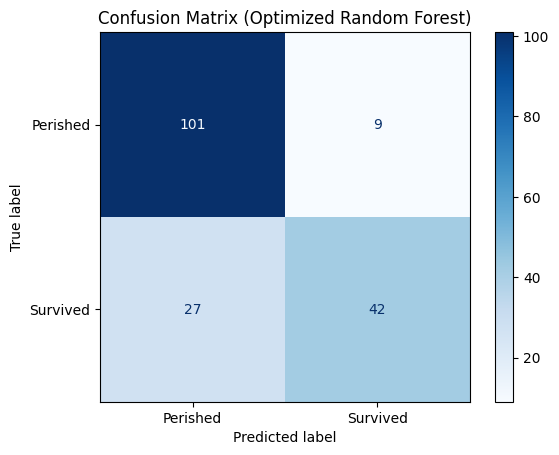

In [ ]:
# 1. Generate the raw confusion matrix values
cm = confusion_matrix(y_test, y_pred_opt)

# 2. Set up the visual display with proper class labels
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Perished', 'Survived'])

# 3. Render the plot
plt.figure(figsize=(6, 6))
display.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix (Optimized Random Forest)")
plt.show()
